# 03 · Validation on simulated data

Before trusting our method on the real returns, we fit it to returns simulated with parameters that we choose: does it recover them, is our tuning a good one, and are its 95% intervals right 95% of the time?

| Reads | Produces | Running time |
|---|---|---|
| `data/returns.csv` (only its length and its maximum-likelihood fit)<br>`tools.py` | `../report/tables/recovery.tex`, `../report/figures/validation_diagnostics.pdf` (report, Section 5)<br>`../report/tables/tuning.tex`, `../report/figures/tuning.pdf` (report, Section 4)<br>`../report/tables/coverage.tex`, `../report/figures/coverage.pdf` (report, Section 5) | about 8 minutes (7 for the 300 fits of Section 4) |

01 Data → 02 Model and sampler → **03 Validation** → 04 Posterior → 05 Risk → 06 Checks

In [1]:
# Setup: libraries, our shared functions and the constants of this notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from tools import (BURN_IN, COLOR_GAUSS, COLOR_OTHER, COLOR_T, autocorr, convergence_checks, es_t,
                   ess, find_map, independence_sampler, log_posterior, metropolis, plot_diagnostics,
                   run_chains, save_figure, save_table, set_style, summarize, to_theta, var_t)

SEED = 2026
rng = np.random.default_rng(SEED)           # for our samplers
data_rng = np.random.default_rng(SEED + 1)  # for the simulated data sets, kept apart

# The real returns: simulated data sets get the same size, and true values close to their fit
y_real = pd.read_csv("data/returns.csv")["y"].to_numpy()
n = len(y_real)
LEVELS = [0.99, 0.999]  # levels of the VaR and ES we validate

# Tuning study (Section 3): step factors c, as in Example 6.6, and iterations per run
STEP_FACTORS = [0.1, 0.3, 0.6, 1.0, 1.5, 2.5, 5.0]
N_TUNE = 20_000

# Coverage study (Section 4): tail regimes, data sets per regime, lighter sampler settings
NUS = [2.5, 4.0, 8.0]
N_SETS = 100
LIGHT_N_ITER, LIGHT_N_PILOT, LIGHT_BURN_IN = 6_000, 2_000, 1_000

set_style()

In [2]:
def quantities(theta):
    """The quantities we validate, from one parameter vector or from draws: mu, sigma, nu, VaR, ES."""
    theta = np.asarray(theta)
    values = {"mu": theta[..., 0], "sigma": theta[..., 1], "nu": theta[..., 2]}
    for level in LEVELS:
        values[f"VaR {100 * level:g}%"] = var_t(theta, level)
        values[f"ES {100 * level:g}%"] = es_t(theta, level)
    return values

## 1. A simulated data set

We simulate $n$ days, as many as in our real data, from the model itself, $y_t = \mu + \sigma\,T_t$ with $T_t$ a standard Student-t with $\nu$ degrees of freedom. As true values we take the maximum-likelihood fit of the real data, rounded, so that the simulated data look like ours. This is the case that matters for our question.

In [3]:
# Maximum-likelihood fit of the real data (SciPy), only to choose realistic true values
nu_mle, mu_mle, sigma_mle = stats.t.fit(y_real)
print(f"Maximum likelihood on the real data: mu = {mu_mle:.5f}, sigma = {sigma_mle:.5f}, nu = {nu_mle:.3f}")

# ASSUMPTION: true values = this fit, rounded
MU_TRUE, SIGMA_TRUE, NU_TRUE = 0.001, 0.007, 2.5
theta_true = np.array([MU_TRUE, SIGMA_TRUE, NU_TRUE])
y_sim = MU_TRUE + SIGMA_TRUE * data_rng.standard_t(NU_TRUE, n)

# Do the simulated returns look like the real ones? (in %)
for name, y in [("simulated", y_sim), ("real", y_real)]:
    beyond_4sd = np.sum(np.abs(y - y.mean()) > 4 * y.std())
    print(f"{name:>9}: sd {100 * y.std():.2f}%, worst day {100 * y.min():.2f}%, "
          f"best day {100 * y.max():.2f}%, days beyond 4 sd {beyond_4sd}")

Maximum likelihood on the real data: mu = 0.00098, sigma = 0.00682, nu = 2.470
simulated: sd 1.44%, worst day -20.16%, best day 25.77%, days beyond 4 sd 39
     real: sd 1.25%, worst day -12.78%, best day 10.76%, days beyond 4 sd 36


## 2. Recovery of the true values

We fit the simulated data with exactly the recipe we will use on the real data (`run_chains`: MAP, 3 pilot rounds, 4 chains of 20,000 iterations, burn-in 2,000). For each parameter, and for the VaR and ES that our question is about, we check whether the true value lies inside the 95% posterior interval. We also run every convergence diagnostic.

In [4]:
# Fit the simulated data with our full recipe
def target(phi):
    """Log posterior of phi given the simulated data."""
    return log_posterior(phi, y_sim)

start = [np.median(y_sim), np.log(y_sim.std()), 0.0]  # the MAP search starts at nu = 3
chains, accept = run_chains(target, start, rng)
theta_draws = to_theta(chains)       # every iteration, burn-in included (for the figure)
kept = theta_draws[:, BURN_IN:]      # the draws we use

In [5]:
# Recovery table: true value, posterior summary, and whether the truth is inside the 95% interval
true_values = quantities(theta_true)
draws = quantities(kept)
rows = {}
for name in draws:
    scale = 1 if name == "nu" else 100  # returns-scale quantities in %
    s = summarize(scale * draws[name])
    truth = scale * true_values[name]
    rows[name] = {"true": truth, "mean": s["mean"], "2.5%": s["2.5%"], "97.5%": s["97.5%"],
                  "inside": s["2.5%"] <= truth <= s["97.5%"],
                  "R-hat": s["R-hat"], "ESS": s["ESS"], "MCSE": s["MCSE"]}
recovery = pd.DataFrame.from_dict(rows, orient="index")
recovery

,true,mean,2.5%,97.5%,inside,R-hat,ESS,MCSE
mu,0.100000,0.106613,0.082284,0.130754,True,1.000362,5760.338925,0.000163
sigma,0.700000,0.696382,0.670631,0.723051,True,1.001423,6900.597113,0.000161
nu,2.500000,2.443699,2.255330,2.648371,True,1.001287,6765.367307,0.001224
VaR 99%,3.647178,3.719154,3.474709,3.995581,True,1.000698,6637.813693,0.001643
ES 99%,6.263949,6.503952,5.800295,7.347934,True,1.000960,6548.906271,0.004940
VaR 99.9%,9.575535,10.001032,8.763055,11.480671,True,1.001002,6551.026120,0.008647
ES 99.9%,16.072638,17.114509,14.206368,20.711219,True,1.001087,6500.075935,0.020818


In [6]:
# Convergence targets, and the table for the report
print("acceptance rates:", accept.round(3))
for check, passed in convergence_checks(recovery, accept).items():
    print("PASS" if passed else "FAIL", check)
print(f"true values inside their 95% interval: {recovery['inside'].sum()} of {len(recovery)}")

labels = {"mu": r"$\mu$ (%)", "sigma": r"$\sigma$ (%)", "nu": r"$\nu$", "VaR 99%": "VaR 99% (%)",
          "ES 99%": "ES 99% (%)", "VaR 99.9%": "VaR 99.9% (%)", "ES 99.9%": "ES 99.9% (%)"}
report_rows = {}
for name in recovery.index:
    d = 3 if name in ["mu", "sigma"] else 2  # decimals shown for this quantity
    r = recovery.loc[name]
    report_rows[labels[name]] = {"True": f"{r['true']:.{d}f}", "Mean": f"{r['mean']:.{d}f}",
                                 "95% interval": f"[{r['2.5%']:.{d}f}, {r['97.5%']:.{d}f}]",
                                 "Inside": "yes" if r["inside"] else "no",
                                 r"$\hat R$": f"{r['R-hat']:.4f}", "ESS": f"{r['ESS']:,.0f}"}
report = pd.DataFrame.from_dict(report_rows, orient="index")
report.index.name = "Quantity"
save_table(report, "recovery.tex")

acceptance rates: [0.299 0.302 0.303 0.3  ]
PASS split-R-hat < 1.01 for every quantity
PASS ESS >= 1,000 for every quantity
PASS acceptance rate in [0.2, 0.5] for every chain
true values inside their 95% interval: 7 of 7


> **[COURSE]** Convergence diagnostics: Ch. 6, Sec. 6.6 (p. 73) and the checklist of App. C.4 (p. 90): dispersed starting points, trace plots, burn-in, split-$\hat R$, autocorrelations and ESS.

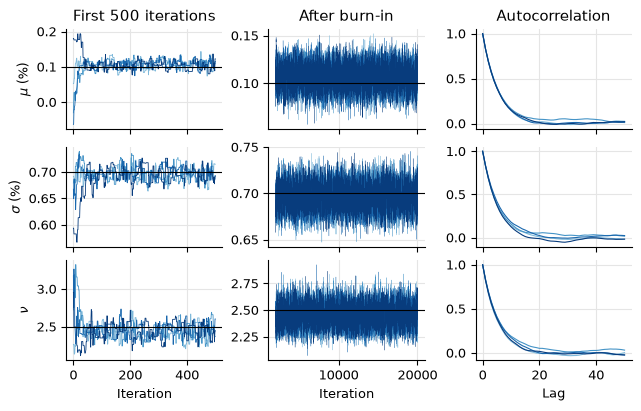

In [7]:
# Traces and autocorrelations of the 4 chains, with the true values in black (mu and sigma in %)
fig = plot_diagnostics(theta_draws * [100, 100, 1], [r"$\mu$ (%)", r"$\sigma$ (%)", r"$\nu$"],
                       truth=theta_true * [100, 100, 1])
save_figure(fig, "validation_diagnostics.pdf")
plt.show()

**What we see.** All seven true values, the three parameters and the four risk measures, lie inside their 95% intervals, and every convergence target passes. The chains start far from the posterior, forget their starting points within about 100 iterations (well before the burn-in of 2,000), then look like a stationary "hairy caterpillar" around the true values, and their autocorrelations die out after about 20 lags.

The simulated returns have a standard deviation and a number of days beyond 4 sd close to the real ones, but larger extreme days: with $\nu = 2.5$, single days can be very large. Notebook 06 asks whether the real data's extremes are plausible under the fitted model.

## 3. Is our tuning a good one?

A random walk needs a step that is neither too small (the chain crawls) nor too large (almost every proposal is rejected). Our recipe uses the proposal covariance $(2.38^2/d)\,\hat\Sigma$, with $\hat\Sigma$ the posterior covariance. To check it, we multiply this step by a factor $c$ and run one chain of 20,000 iterations for each $c$, from the posterior mean, on the same posterior. We compare the chains by their **ESS per 1,000 iterations**. Every iteration costs one evaluation of the posterior, whatever $c$, so this ranks the settings exactly as ESS per second would, and it does not depend on the computer.

Two other samplers complete the comparison:
- a random walk that **ignores the correlations** between parameters (a diagonal proposal with the same variances), to see what the pilot covariance brings: $\sigma$ and $\nu$ trade off (a heavier tail can be offset by a smaller scale), which we expected to slow the chains down;
- an **independence sampler**, whose proposals come from a fixed Student-t with 4 degrees of freedom, centred at the MAP with the Laplace covariance, and are accepted with probability $\min\{1, w(\phi')/w(\phi)\}$, where $w = \tilde\pi/g$.

> **[COURSE]** Choosing the step size: Ch. 6, Example 6.6 and Sec. 6.5 (p. 72); tuning guidelines: App. C.3 (p. 90). Pilot covariance: Example 6.2 (p. 69). Independence sampler: Sec. 6.3 (p. 70).

In [8]:
# Posterior covariance of phi from the recovery fit, and our tuned step (c = 1)
phi_kept = chains[:, BURN_IN:].reshape(-1, 3)
cov_post = np.cov(phi_kept, rowvar=False)
phi_mean = phi_kept.mean(axis=0)
L_tuned = 2.38 / np.sqrt(3) * np.linalg.cholesky(cov_post)
print("posterior correlations of phi = (mu, log sigma, log(nu - 2)):")
print(np.corrcoef(phi_kept, rowvar=False).round(2))

def efficiency(draws_phi, accept_rate):
    """Acceptance rate, lag-1 autocorrelation of nu, and ESS per 1,000 iterations of mu, sigma, nu."""
    theta = to_theta(draws_phi[BURN_IN:])
    row = {"acceptance": accept_rate, "lag-1 autocorrelation of nu": autocorr(theta[:, 2], 1)}
    for i, name in enumerate(["mu", "sigma", "nu"]):
        row[f"ESS per 1,000 ({name})"] = 1000 * ess(theta[np.newaxis, :, i]) / len(theta)
    return row

posterior correlations of phi = (mu, log sigma, log(nu - 2)):
[[ 1.   -0.02 -0.02]
 [-0.02  1.    0.61]
 [-0.02  0.61  1.  ]]


In [9]:
# Random walks with the step multiplied by c
rows = {}
for c in STEP_FACTORS:
    draws_phi, rate = metropolis(target, phi_mean, c * L_tuned, N_TUNE, rng)
    rows[f"random walk, c = {c:g}"] = efficiency(draws_phi, rate)

# The same random walk (c = 1) with the correlations ignored: a diagonal proposal
L_diagonal = 2.38 / np.sqrt(3) * np.diag(np.sqrt(np.diag(cov_post)))
draws_phi, rate = metropolis(target, phi_mean, L_diagonal, N_TUNE, rng)
rows["random walk, diagonal, c = 1"] = efficiency(draws_phi, rate)

In [10]:
# Independence sampler (tools.py): proposals from a Student-t4 centred at the MAP, Laplace scale
mode, laplace = find_map(target, start)
draws_phi, rate = independence_sampler(target, mode, laplace, N_TUNE, rng)
rows["independence sampler, Student-t4 at the MAP"] = efficiency(draws_phi, rate)

tuning = pd.DataFrame.from_dict(rows, orient="index")
tuning["smallest ESS per 1,000"] = tuning[["ESS per 1,000 (mu)", "ESS per 1,000 (sigma)",
                                           "ESS per 1,000 (nu)"]].min(axis=1)
tuning.round(2)

,acceptance,lag-1 autocorrelation of nu,"ESS per 1,000 (mu)","ESS per 1,000 (sigma)","ESS per 1,000 (nu)","smallest ESS per 1,000"
"random walk, c = 0.1",0.90,0.99,3.04,4.25,4.87,3.04
"random walk, c = 0.3",0.74,0.93,32.68,24.08,35.04,24.08
"random walk, c = 0.6",0.52,0.86,65.15,62.02,64.84,62.02
"random walk, c = 1",0.31,0.82,86.19,87.26,95.17,86.19
"random walk, c = 1.5",0.16,0.87,73.33,57.98,57.89,57.89
"random walk, c = 2.5",0.06,0.94,35.29,33.23,30.40,30.40
"random walk, c = 5",0.01,0.99,9.39,4.88,4.35,4.35
"random walk, diagonal, c = 1",0.26,0.87,76.96,67.05,64.74,64.74
"independence sampler, Student-t4 at the MAP",0.75,0.31,633.68,593.98,486.65,486.65


In [11]:
# Compact table for the report: acceptance rate and ESS per 1,000 iterations of each parameter
short_names = {"random walk, diagonal, c = 1": "Random walk, diagonal, $c = 1$",
               "independence sampler, Student-t4 at the MAP": "Independence sampler"}
for c in STEP_FACTORS:
    short_names[f"random walk, c = {c:g}"] = f"Random walk, $c = {c:g}$"

tuning_report = pd.DataFrame({
    "Acceptance": [f"{x:.2f}" for x in tuning["acceptance"]],
    r"ESS/1,000: $\mu$": [f"{x:.0f}" for x in tuning["ESS per 1,000 (mu)"]],
    r"$\sigma$": [f"{x:.0f}" for x in tuning["ESS per 1,000 (sigma)"]],
    r"$\nu$": [f"{x:.0f}" for x in tuning["ESS per 1,000 (nu)"]]},
    index=[short_names[name] for name in tuning.index])
tuning_report.index.name = "Sampler"
save_table(tuning_report, "tuning.tex")

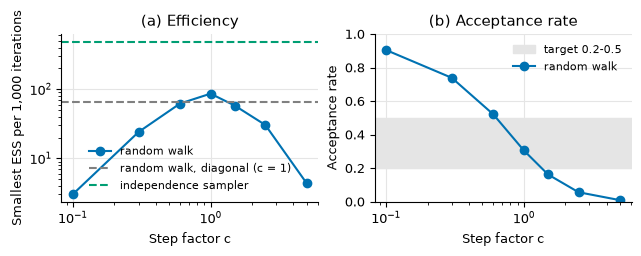

In [12]:
# Figure: (a) efficiency and (b) acceptance rate against the step factor c
random_walks = tuning.loc[[f"random walk, c = {c:g}" for c in STEP_FACTORS]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.3, 2.4))

ax1.plot(STEP_FACTORS, random_walks["smallest ESS per 1,000"], "o-", color=COLOR_T,
         label="random walk")
ax1.axhline(tuning.loc["random walk, diagonal, c = 1", "smallest ESS per 1,000"], color="grey",
            linestyle="--", label="random walk, diagonal (c = 1)")
ax1.axhline(tuning.loc["independence sampler, Student-t4 at the MAP", "smallest ESS per 1,000"],
            color=COLOR_OTHER, linestyle="--", label="independence sampler")
ax1.set(xscale="log", yscale="log", xlabel="Step factor c",
        ylabel="Smallest ESS per 1,000 iterations", title="(a) Efficiency")
ax1.legend(loc="lower center")

ax2.axhspan(0.2, 0.5, color="#E5E5E5", label="target 0.2-0.5")
ax2.plot(STEP_FACTORS, random_walks["acceptance"], "o-", color=COLOR_T, label="random walk")
ax2.set(xscale="log", xlabel="Step factor c", ylabel="Acceptance rate", ylim=(0, 1),
        title="(b) Acceptance rate")
ax2.legend()

save_figure(fig, "tuning.pdf")
plt.show()

**What we see.**
- **(a)** Our step, $c = 1$, is the best random walk: about 86 effective draws per 1,000 iterations for the slowest parameter, against 3 to 5 for steps ten times smaller or five times larger. The first is too timid (90% of the proposals accepted, the chain crawls); the second, too bold (1% accepted, the chain sticks). **(b)** Its acceptance rate, 0.31, lies inside the 0.2–0.5 target.
- Ignoring the correlation of 0.61 between $\log\sigma$ and $\log(\nu-2)$ costs about a quarter of the efficiency (65): the pilot covariance is worth having.
- The independence sampler is more than five times more efficient again. With 5,031 days, the posterior of $\phi$ is close to the Gaussian of the Laplace approximation, so a heavier-tailed proposal built on it fits well, as in Example 6.3 of the notes. We keep the random walk as our main sampler: its efficiency is ample (thousands of effective draws per fit), and it needs only local information, while an independence sampler is only as good as its global approximation. The same Laplace Student-t proposal returns in notebook 05, for importance sampling.

## 4. Coverage: are the 95% intervals right 95% of the time?

One data set cannot tell whether our intervals are **calibrated**. We repeat the whole fit on 100 simulated data sets in each of three tail regimes, $\nu \in \{2.5, 4, 8\}$ (with $\mu = 0.001$, $\sigma = 0.007$ and $n$ days), so 300 fits, and count how often each 95% interval contains the true value. Each fit uses our full recipe with lighter settings (pilot rounds of 2,000 iterations, 4 chains of 6,000 iterations, burn-in 1,000), and is checked against the convergence targets.

With 100 data sets, the number of intervals that contain the truth is Binomial(100, 0.95) for a calibrated method, so its coverage should fall in the central 95% band of that distribution. We also look at the **standardized errors** (truth − posterior mean)/posterior sd: for a calibrated method, their mean is close to 0 (no bias) and their standard deviation close to 1 (intervals of the right width).

> **[COURSE]** Checking the coverage of intervals by simulation: Ch. 3, Sec. 3.3.1 (p. 42). The Monte Carlo error of a proportion: Ch. 1, Proposition 1.2 (p. 24).

In [13]:
# 300 fits: simulate each data set, fit it, and record whether each 95% interval contains the truth
records = []
for nu_true in NUS:
    truth = quantities([MU_TRUE, SIGMA_TRUE, nu_true])
    for k in range(N_SETS):
        y_k = MU_TRUE + SIGMA_TRUE * data_rng.standard_t(nu_true, n)

        def target_k(phi):
            """Log posterior of phi given the simulated data set k."""
            return log_posterior(phi, y_k)

        start_k = [np.median(y_k), np.log(y_k.std()), 0.0]
        chains_k, accept_k = run_chains(target_k, start_k, rng, n_iter=LIGHT_N_ITER,
                                        n_pilot=LIGHT_N_PILOT)
        draws_k = quantities(to_theta(chains_k[:, LIGHT_BURN_IN:]))

        # Did this fit converge? (the three parameters against our targets)
        params = pd.DataFrame([summarize(draws_k[name]) for name in ["mu", "sigma", "nu"]])
        converged = all(convergence_checks(params, accept_k).values())

        # One record per quantity: its 95% interval, and whether it contains the truth
        for name, values in draws_k.items():
            lo, hi = np.quantile(values, [0.025, 0.975])
            records.append({"nu_true": nu_true, "data_set": k, "quantity": name, "lo": lo, "hi": hi,
                            "mean": values.mean(), "truth": truth[name],
                            "inside": lo <= truth[name] <= hi,
                            "z": (truth[name] - values.mean()) / values.std(),
                            "converged": converged})
results = pd.DataFrame(records)
print(f"{len(results) // len(draws_k)} fits done")

300 fits done


In [14]:
# Coverage (%) of the 95% intervals, per regime and quantity, and the number of fits that converged
order = list(quantities(theta_true).keys())
coverage = 100 * results.pivot_table(index="nu_true", columns="quantity", values="inside")[order]
fits = results[results["quantity"] == "mu"]
coverage["fits converged"] = fits.groupby("nu_true")["converged"].sum()

# A calibrated coverage is Binomial(N_SETS, 0.95) / N_SETS: its central 95% band, and the chance
# that a calibrated coverage still falls outside that band
lo, hi = stats.binom.ppf([0.025, 0.975], N_SETS, 0.95)
band = 100 * np.array([lo, hi]) / N_SETS
p_outside = stats.binom.cdf(lo - 1, N_SETS, 0.95) + stats.binom.sf(hi, N_SETS, 0.95)
inside_band = (coverage[order] >= band[0]) & (coverage[order] <= band[1])
print(f"calibrated band for {N_SETS} data sets: [{band[0]:.0f}%, {band[1]:.0f}%]")
print(f"coverages inside the band: {inside_band.sum().sum()} of {inside_band.size}")
print(f"by chance alone, each calibrated coverage falls outside the band with probability "
      f"{p_outside:.3f}: {inside_band.size * p_outside:.1f} expected outside among {inside_band.size}")
p_any = 1 - (1 - p_outside) ** inside_band.size
print(f"probability that at least one of {inside_band.size} calibrated coverages falls outside: {p_any:.2f}")
coverage

calibrated band for 100 data sets: [90%, 99%]
coverages inside the band: 20 of 21
by chance alone, each calibrated coverage falls outside the band with probability 0.017: 0.4 expected outside among 21
probability that at least one of 21 calibrated coverages falls outside: 0.31


quantity,mu,sigma,nu,VaR 99%,ES 99%,VaR 99.9%,ES 99.9%,fits converged
nu_true,,,,,,,,
2.5,94.0,98.0,97.0,97.0,98.0,98.0,97.0,100
4.0,96.0,89.0,91.0,95.0,94.0,94.0,94.0,100
8.0,93.0,93.0,94.0,95.0,95.0,95.0,95.0,100


In [15]:
# Standardized errors (truth - mean) / sd: mean close to 0 and sd close to 1 if calibrated
z_mean = results.pivot_table(index="nu_true", columns="quantity", values="z", aggfunc="mean")[order]
z_sd = results.pivot_table(index="nu_true", columns="quantity", values="z", aggfunc="std")[order]
print("mean of the standardized errors:")
print(z_mean.round(2))
print("\nsd of the standardized errors:")
print(z_sd.round(2))

mean of the standardized errors:
quantity    mu  sigma    nu  VaR 99%  ES 99%  VaR 99.9%  ES 99.9%
nu_true                                                          
2.5       0.14  -0.21 -0.08    -0.03    0.02       0.03      0.05
4.0       0.23  -0.27 -0.13    -0.06    0.03       0.06      0.09
8.0       0.16  -0.18 -0.11    -0.05    0.03       0.06      0.09

sd of the standardized errors:
quantity    mu  sigma    nu  VaR 99%  ES 99%  VaR 99.9%  ES 99.9%
nu_true                                                          
2.5       0.97   0.88  0.99     1.03    1.01       1.01      0.99
4.0       0.93   1.14  1.05     1.01    1.04       1.05      1.06
8.0       1.09   1.05  1.01     0.95    1.00       1.03      1.06


In [16]:
# Table for the report: coverage in %, one row per regime
coverage_report = coverage.astype(int)
coverage_report.index = [rf"$\nu = {nu:g}$" for nu in coverage_report.index]
coverage_report.index.name = "Regime"
coverage_report.columns = [labels[name].replace(" (%)", "") for name in order] + ["Converged"]
save_table(coverage_report, "coverage.tex")

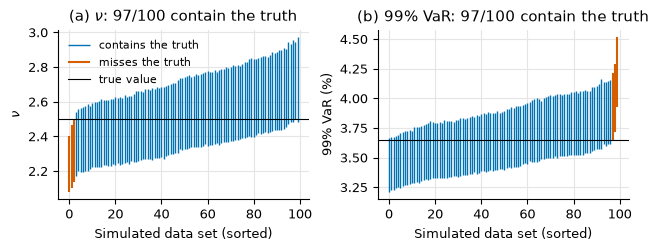

In [17]:
# Figure: the 100 intervals of nu and of the 99% VaR in the nu = 2.5 regime, sorted by posterior mean
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.4))
panels = [(axes[0], "nu", 1, r"$\nu$", r"(a) $\nu$"), (axes[1], "VaR 99%", 100, "99% VaR (%)", "(b) 99% VaR")]
for ax, name, scale, label, title in panels:
    sub = results[(results["nu_true"] == 2.5) & (results["quantity"] == name)].sort_values("mean")
    x = np.arange(len(sub))
    hit = sub["inside"].to_numpy()
    ax.vlines(x[hit], scale * sub["lo"][hit], scale * sub["hi"][hit], color=COLOR_T, linewidth=1,
              label="contains the truth")
    ax.vlines(x[~hit], scale * sub["lo"][~hit], scale * sub["hi"][~hit], color=COLOR_GAUSS,
              linewidth=1.5, label="misses the truth")
    ax.axhline(scale * sub["truth"].iloc[0], color="black", linewidth=0.8, label="true value")
    ax.set(xlabel="Simulated data set (sorted)", ylabel=label,
           title=f"{title}: {hit.sum()}/{len(sub)} contain the truth")
axes[0].legend(loc="upper left")
save_figure(fig, "coverage.pdf")
plt.show()

**What we see.** All 300 fits converged. Twenty of the 21 coverages fall inside the calibrated band; the exception, $\sigma$ in the $\nu = 4$ regime at 89%, is one point below it. Even for a calibrated method, at least one of 21 coverages falls outside the band in about 30% of such studies (printed above), so a single exception is not a warning sign on its own. The standardized errors confirm the picture: their means stay within ±0.27 and their standard deviations between 0.88 and 1.14, so the intervals are close to unbiased and of the right width. The small positive mean for $\mu$ is the prior, which pulls $\mu = 0.001$ slightly towards 0.

Most importantly for our question, the intervals of the **VaR and ES are calibrated in every regime** (94% to 98%), with standardized errors close to 0. In the $\nu = 2.5$ regime (figure), the few misses all go towards heavier tails, $\nu$ too low and VaR too high: data sets whose extreme days happen to be unusually large.

## 5. What we found

In [18]:
# Numbers quoted in the report
print(f"True values: mu = {MU_TRUE}, sigma = {SIGMA_TRUE}, nu = {NU_TRUE} "
      f"(maximum likelihood on the real data: {mu_mle:.5f}, {sigma_mle:.5f}, {nu_mle:.2f})")
print(f"Recovery: {recovery['inside'].sum()} of {len(recovery)} true values inside their 95% interval; "
      f"R-hat <= {recovery['R-hat'].max():.4f}, ESS >= {recovery['ESS'].min():,.0f}, "
      f"acceptance {accept.min():.2f}-{accept.max():.2f}")
best = tuning.loc[[f"random walk, c = {c:g}" for c in STEP_FACTORS], "smallest ESS per 1,000"]
print(f"Tuning: best random walk at c = {STEP_FACTORS[int(np.argmax(best.to_numpy()))]:g}; "
      f"smallest ESS per 1,000 at c = 1: {tuning.loc['random walk, c = 1', 'smallest ESS per 1,000']:.0f}, "
      f"diagonal: {tuning.loc['random walk, diagonal, c = 1', 'smallest ESS per 1,000']:.0f}, "
      f"independence sampler: "
      f"{tuning.loc['independence sampler, Student-t4 at the MAP', 'smallest ESS per 1,000']:.0f}")
print(f"Coverage: {coverage[order].min().min():.0f}% to {coverage[order].max().max():.0f}%, "
      f"{inside_band.sum().sum()} of {inside_band.size} inside the calibrated band "
      f"[{band[0]:.0f}%, {band[1]:.0f}%] (at least one outside by chance: probability {p_any:.2f}); "
      f"{int(coverage['fits converged'].sum())} of {len(NUS) * N_SETS} fits converged")
print(f"Standardized errors: mean {z_mean.min().min():.2f} to {z_mean.max().max():.2f}, "
      f"sd {z_sd.min().min():.2f} to {z_sd.max().max():.2f}")

True values: mu = 0.001, sigma = 0.007, nu = 2.5 (maximum likelihood on the real data: 0.00098, 0.00682, 2.47)
Recovery: 7 of 7 true values inside their 95% interval; R-hat <= 1.0014, ESS >= 5,760, acceptance 0.30-0.30
Tuning: best random walk at c = 1; smallest ESS per 1,000 at c = 1: 86, diagonal: 65, independence sampler: 487
Coverage: 89% to 98%, 20 of 21 inside the calibrated band [90%, 99%] (at least one outside by chance: probability 0.31); 300 of 300 fits converged
Standardized errors: mean -0.27 to 0.23, sd 0.88 to 1.14


- **Recovery:** on data like ours, the method recovers all seven true values (parameters, VaR and ES), and every convergence target passes.
- **Tuning:** our step is the best random walk and the pilot covariance helps; an independence sampler would be more than five times more efficient on this near-Gaussian posterior, but we keep the random walk, which needs no global approximation.
- **Calibration:** over 300 fits in three tail regimes, the 95% intervals contain the truth 89% to 98% of the time, inside the calibrated band except one, an exception that chance alone produces in about 30% of such studies; the VaR and ES, the quantities we report, are calibrated in every regime.

**Next:** `04_posterior.ipynb` fits the real data, with the Gaussian model as a benchmark.